# FashionMNIST — CNN Training with CLAHE

**Project:** fashionmnist-classification  
**Data:** 1/3 of training set (20,000 samples) + full 10,000 test set  
**Preprocessing:** Normalize → **CLAHE contrast enhancement** → Standardize → Reshape  
**Model:** Same CNN as v1 (2 conv blocks + dense head)  
**Regularization:** L2 weight decay + Gaussian noise augmentation  
**Training:** LR schedule (ReduceLROnPlateau) + early stopping  

---

### Comparison with v1
| | v1 (no CLAHE) | v2 (CLAHE) |
|---|---|---|
| Test accuracy | 89.07% | ? |
| Shirt (worst class) | 62.9% | ? |
| Sandal | 98.0% | ? |

## 1. Imports

In [1]:
import os
import json
import boto3
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from skimage import exposure
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cpu


## 2. Load FashionMNIST from S3

In [2]:
BUCKET = 'sagemaker-fashionmnist-328996809692-jy8sv90u'
PREFIX = 'fashionmnist/raw'
LOCAL_DIR = '/tmp/fashionmnist'

s3 = boto3.client('s3', region_name='us-east-2')
raw_dir = os.path.join(LOCAL_DIR, 'FashionMNIST', 'raw')
os.makedirs(raw_dir, exist_ok=True)

response = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX)
for obj in response.get('Contents', []):
    key = obj['Key']
    fname = os.path.basename(key)
    if fname:
        local_path = os.path.join(raw_dir, fname)
        if not os.path.exists(local_path):
            s3.download_file(BUCKET, key, local_path)
            print(f"Downloaded {fname}")

train_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=True, download=False)
test_dataset = datasets.FashionMNIST(root=LOCAL_DIR, train=False, download=False)

X_all = train_dataset.data.numpy().astype(np.float32) / 255.0
y_all = train_dataset.targets.numpy()
X_test = test_dataset.data.numpy().astype(np.float32) / 255.0
y_test = test_dataset.targets.numpy()

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
print(f"Full train: {X_all.shape}, Test: {X_test.shape}")

Full train: (60000, 28, 28), Test: (10000, 28, 28)


## 3. Subsample — 1/3 of Training Data

Same stratified split as v1 for fair comparison.

In [3]:
subset_size = len(X_all) // 3  # 20,000
rng = np.random.RandomState(SEED)

indices = []
for cls in range(10):
    cls_indices = np.where(y_all == cls)[0]
    n_select = len(cls_indices) // 3
    selected = rng.choice(cls_indices, n_select, replace=False)
    indices.extend(selected)

indices = np.array(indices)
rng.shuffle(indices)

X_subset = X_all[indices]
y_subset = y_all[indices]

print(f"Subset: {X_subset.shape} ({len(y_subset)} samples)")
print(f"Class balance: {np.bincount(y_subset)}")

Subset: (20000, 28, 28) (20000 samples)
Class balance: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


## 4. Apply CLAHE Contrast Enhancement

CLAHE (Contrast Limited Adaptive Histogram Equalization) improves local contrast — especially for dim classes like Sandal, Sneaker, and Shirt. We apply it uniformly since the effect is subtle on already-bright images.

In [4]:
def apply_clahe_batch(images, clip_limit=0.03):
    """Apply CLAHE to a batch of normalized [0,1] grayscale images.
    
    Args:
        images: (N, H, W) float32 in [0, 1]
        clip_limit: contrast limit (lower = more subtle)
    Returns:
        Enhanced images, same shape
    """
    enhanced = np.empty_like(images)
    for i in range(images.shape[0]):
        enhanced[i] = exposure.equalize_adapthist(
            images[i], clip_limit=clip_limit
        )
    return enhanced

print("Applying CLAHE to training subset...")
X_subset_clahe = apply_clahe_batch(X_subset, clip_limit=0.03)
print(f"Done. Shape: {X_subset_clahe.shape}")

print("Applying CLAHE to test set...")
X_test_clahe = apply_clahe_batch(X_test, clip_limit=0.03)
print(f"Done. Shape: {X_test_clahe.shape}")

Applying CLAHE to training subset...


Done. Shape: (20000, 28, 28)
Applying CLAHE to test set...


Done. Shape: (10000, 28, 28)


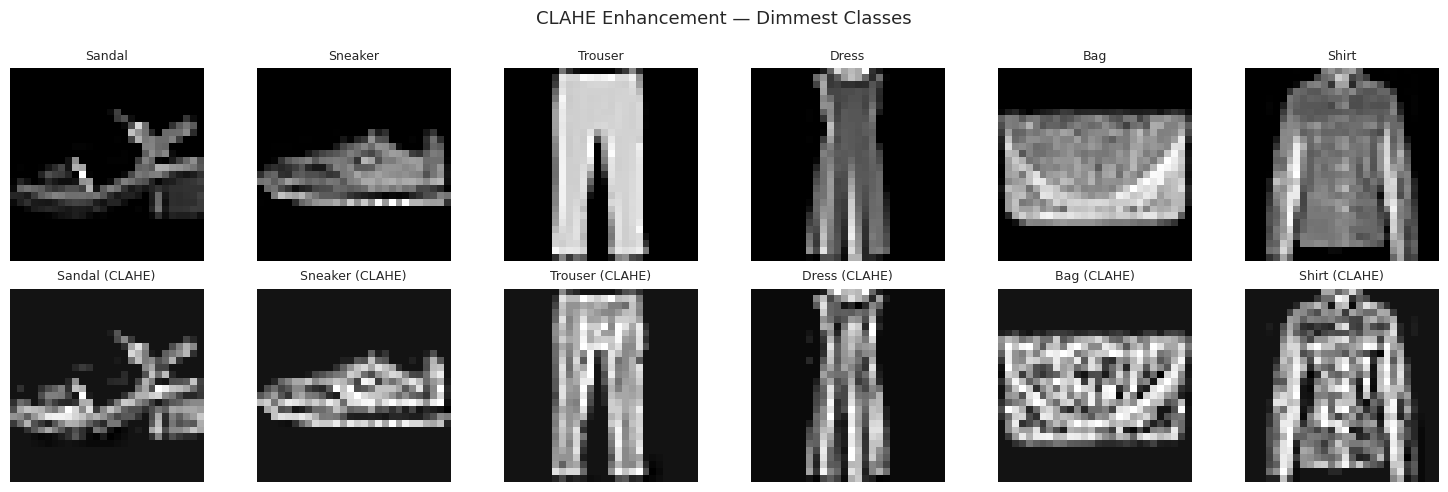

In [5]:
# Visualize: original vs CLAHE for dimmest classes
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
dimmest = [5, 7, 1, 3, 8, 6]  # Sandal, Sneaker, Trouser, Dress, Bag, Shirt

for col, cls in enumerate(dimmest):
    idx = np.where(y_subset == cls)[0][0]
    axes[0, col].imshow(X_subset[idx], cmap='gray', vmin=0, vmax=1)
    axes[0, col].set_title(class_names[cls], fontsize=9)
    axes[0, col].axis('off')
    
    axes[1, col].imshow(X_subset_clahe[idx], cmap='gray', vmin=0, vmax=1)
    axes[1, col].set_title(f'{class_names[cls]} (CLAHE)', fontsize=9)
    axes[1, col].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=10)
axes[1, 0].set_ylabel('CLAHE', fontsize=10)
fig.suptitle('CLAHE Enhancement — Dimmest Classes', fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# Reshape for CNN and standardize
# Use stats from the CLAHE-enhanced subset (not original) for consistency
mean = X_subset_clahe.mean()
std = X_subset_clahe.std()

X_subset_cnn = (X_subset_clahe - mean) / std
X_test_cnn = (X_test_clahe - mean) / std

X_subset_cnn = X_subset_cnn.reshape(-1, 1, 28, 28)
X_test_cnn = X_test_cnn.reshape(-1, 1, 28, 28)

print(f"CLAHE stats: mean={mean:.4f}, std={std:.4f}")
print(f"Train: {X_subset_cnn.shape}, range=[{X_subset_cnn.min():.2f}, {X_subset_cnn.max():.2f}]")
print(f"Test:  {X_test_cnn.shape}, range=[{X_test_cnn.min():.2f}, {X_test_cnn.max():.2f}]")

CLAHE stats: mean=0.3016, std=0.3038
Train: (20000, 1, 28, 28), range=[-0.99, 2.30]
Test:  (10000, 1, 28, 28), range=[-0.99, 2.30]


In [7]:
# Create PyTorch datasets
X_tensor = torch.from_numpy(X_subset_cnn).float()
y_tensor = torch.from_numpy(y_subset).long()
X_test_tensor = torch.from_numpy(X_test_cnn).float()
y_test_tensor = torch.from_numpy(y_test).long()

full_train = TensorDataset(X_tensor, y_tensor)
test_ds = TensorDataset(X_test_tensor, y_test_tensor)

train_size = int(0.8 * len(full_train))  # 16,000
val_size = len(full_train) - train_size   #  4,000
train_ds, val_ds = random_split(full_train, [train_size, val_size],
                                  generator=torch.Generator().manual_seed(SEED))

BATCH_SIZE = 64
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

Train: 16000, Val: 4000, Test: 10000


## 5. Define CNN Model

Same architecture as v1 for a fair comparison.

In [8]:
class GaussianNoise(nn.Module):
    """Additive Gaussian noise — only active during training."""
    def __init__(self, std=0.1):
        super().__init__()
        self.std = std

    def forward(self, x):
        if self.training and self.std > 0:
            noise = torch.randn_like(x) * self.std
            return x + noise
        return x


class FashionCNN(nn.Module):
    def __init__(self, noise_std=0.1):
        super().__init__()
        self.noise = GaussianNoise(std=noise_std)
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(2)
        self.dropout1 = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.dropout2 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.noise(x)
        x = self.pool1(torch.relu(self.bn1(self.conv1(x))))
        x = self.pool2(torch.relu(self.bn2(self.conv2(x))))
        x = self.dropout1(x)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.dropout2(x)
        x = self.fc2(x)
        return x

model = FashionCNN(noise_std=0.1).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total params: {total_params:,}")

Total params: 421,834


## 6. Training Loop with Early Stopping & LR Schedule

Same hyperparameters as v1 for fair comparison.

In [9]:
EPOCHS = 15
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE_LR = 3
PATIENCE_STOP = 3
FACTOR = 0.5

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=FACTOR, patience=PATIENCE_LR
)

best_val_loss = float('inf')
best_model_state = None
epochs_no_improve = 0

train_losses, val_losses = [], []
train_accs, val_accs = [], []
lr_history = []

print(f"Training for up to {EPOCHS} epochs (early stop patience={PATIENCE_STOP})")
print(f"LR={LR}, weight_decay={WEIGHT_DECAY}, batch_size={BATCH_SIZE}")
print(f"Data: CLAHE-enhanced (clip_limit=0.03)")
print("-" * 70)

Training for up to 15 epochs (early stop patience=3)
LR=0.001, weight_decay=0.0001, batch_size=64
Data: CLAHE-enhanced (clip_limit=0.03)
----------------------------------------------------------------------


In [10]:
for epoch in range(EPOCHS):
    # --- Train ---
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch_X, batch_y in train_loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_X.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(batch_y).sum().item()
        total += batch_y.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- Validate ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            val_loss += loss.item() * batch_X.size(0)
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(batch_y).sum().item()
            val_total += batch_y.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    lr_history.append(optimizer.param_groups[0]['lr'])

    scheduler.step(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    print(f"Epoch {epoch+1:2d}/{EPOCHS} | "
          f"Train: {train_loss:.4f} / {train_acc:.4f} | "
          f"Val: {val_loss:.4f} / {val_acc:.4f} | "
          f"LR: {optimizer.param_groups[0]['lr']:.2e} | "
          f"{'★' if epochs_no_improve == 0 else f'no improve ({epochs_no_improve}/{PATIENCE_STOP})'}")

    if epochs_no_improve >= PATIENCE_STOP:
        print(f"\nEarly stopping at epoch {epoch+1} (no improvement for {PATIENCE_STOP} epochs)")
        break

model.load_state_dict(best_model_state)
print(f"\nBest val loss: {best_val_loss:.4f}")
print("Best model weights restored.")

Epoch  1/15 | Train: 0.7370 / 0.7372 | Val: 0.3693 / 0.8760 | LR: 1.00e-03 | ★


Epoch  2/15 | Train: 0.4639 / 0.8335 | Val: 0.3128 / 0.8868 | LR: 1.00e-03 | ★


Epoch  3/15 | Train: 0.4063 / 0.8531 | Val: 0.2982 / 0.8908 | LR: 1.00e-03 | ★


Epoch  4/15 | Train: 0.3806 / 0.8629 | Val: 0.2970 / 0.8875 | LR: 1.00e-03 | ★


Epoch  5/15 | Train: 0.3499 / 0.8783 | Val: 0.2844 / 0.8905 | LR: 1.00e-03 | ★


Epoch  6/15 | Train: 0.3324 / 0.8761 | Val: 0.2706 / 0.8990 | LR: 1.00e-03 | ★


... (4 outputs left out)

Epoch 11/15 | Train: 0.2517 / 0.9061 | Val: 0.2437 / 0.9103 | LR: 1.00e-03 | ★


Epoch 12/15 | Train: 0.2418 / 0.9096 | Val: 0.2792 / 0.8995 | LR: 1.00e-03 | no improve (1/3)


Epoch 13/15 | Train: 0.2262 / 0.9159 | Val: 0.2543 / 0.9113 | LR: 1.00e-03 | no improve (2/3)


Epoch 14/15 | Train: 0.2157 / 0.9214 | Val: 0.2570 / 0.9087 | LR: 1.00e-03 | no improve (3/3)

Early stopping at epoch 14 (no improvement for 3 epochs)

Best val loss: 0.2437
Best model weights restored.


## 7. Training Curves

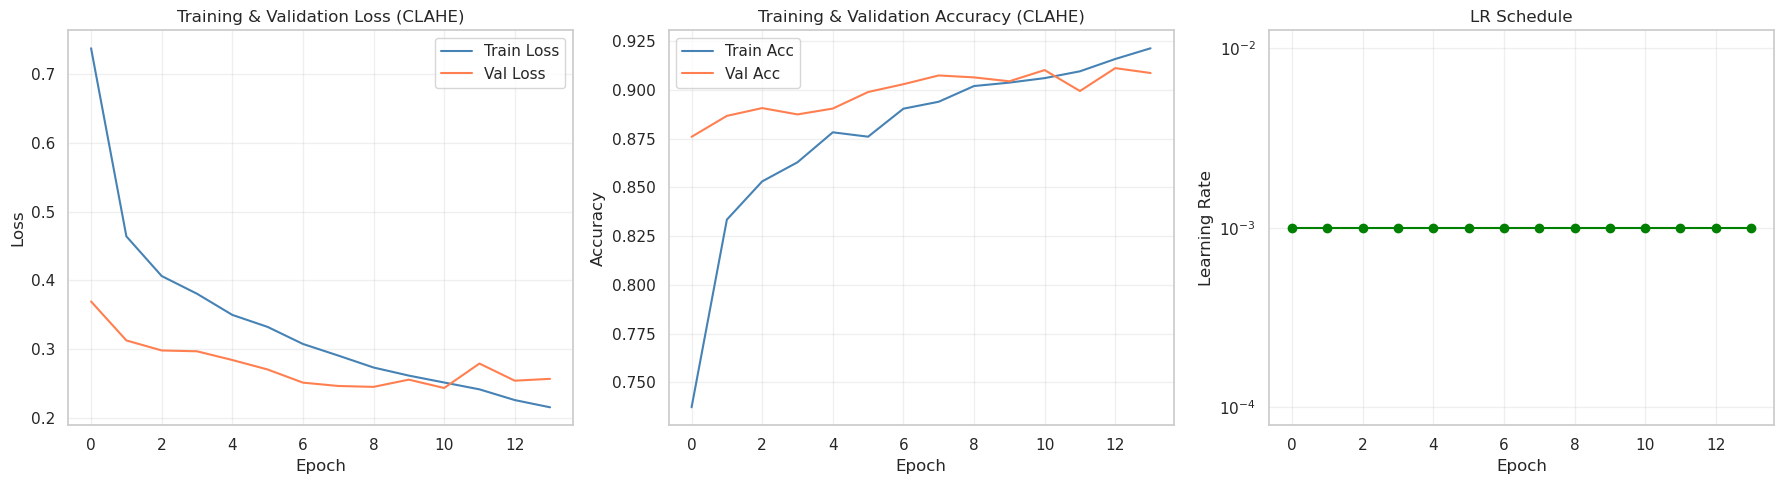

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(train_losses, label='Train Loss', color='steelblue')
axes[0].plot(val_losses, label='Val Loss', color='coral')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss (CLAHE)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(train_accs, label='Train Acc', color='steelblue')
axes[1].plot(val_accs, label='Val Acc', color='coral')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training & Validation Accuracy (CLAHE)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(lr_history, color='green', marker='o')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].set_title('LR Schedule')
axes[2].set_yscale('log')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Evaluation on Test Set

In [12]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)
        outputs = model(batch_X)
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(batch_y.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = (all_preds == all_labels).mean()
print(f"Test Accuracy: {test_acc:.4f} ({test_acc*100:.2f}%)")
print()
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

Test Accuracy: 0.8984 (89.84%)

              precision    recall  f1-score   support

 T-shirt/top     0.8797    0.8120    0.8445      1000
     Trouser     0.9888    0.9730    0.9808      1000
    Pullover     0.8183    0.8870    0.8512      1000
       Dress     0.8558    0.9080    0.8811      1000
        Coat     0.8363    0.8530    0.8446      1000
      Sandal     0.9778    0.9710    0.9744      1000
       Shirt     0.7446    0.6880    0.7152      1000
     Sneaker     0.9396    0.9640    0.9516      1000
         Bag     0.9750    0.9760    0.9755      1000
  Ankle boot     0.9675    0.9520    0.9597      1000

    accuracy                         0.8984     10000
   macro avg     0.8983    0.8984    0.8979     10000
weighted avg     0.8983    0.8984    0.8979     10000



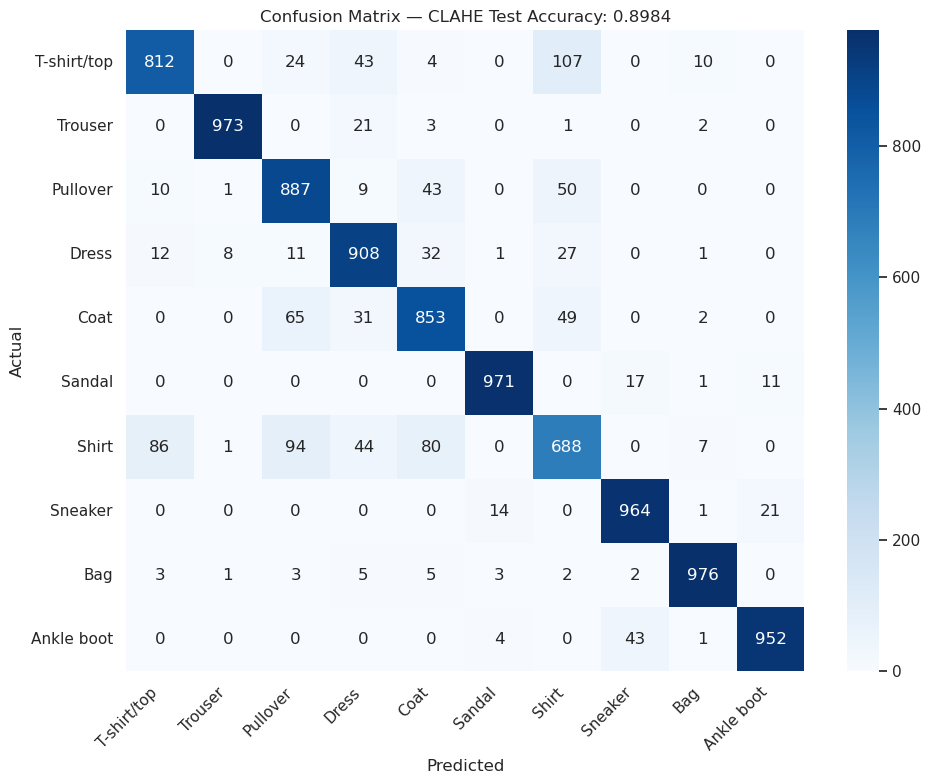

In [13]:
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix — CLAHE Test Accuracy: {test_acc:.4f}')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [14]:
print("Per-class accuracy:")
for i, name in enumerate(class_names):
    cls_mask = all_labels == i
    cls_acc = (all_preds[cls_mask] == all_labels[cls_mask]).mean()
    print(f"  {name:15s}: {cls_acc:.4f} ({cls_acc*100:.1f}%)")

Per-class accuracy:
  T-shirt/top    : 0.8120 (81.2%)
  Trouser        : 0.9730 (97.3%)
  Pullover       : 0.8870 (88.7%)
  Dress          : 0.9080 (90.8%)
  Coat           : 0.8530 (85.3%)
  Sandal         : 0.9710 (97.1%)
  Shirt          : 0.6880 (68.8%)
  Sneaker        : 0.9640 (96.4%)
  Bag            : 0.9760 (97.6%)
  Ankle boot     : 0.9520 (95.2%)


## 9. Comparison: v1 (no CLAHE) vs v2 (CLAHE)

In [15]:
# v1 results (from manifests)
v1_path = '/home/sagemaker-user/fashionmnist-classification/manifests/training-results-v1.json'
with open(v1_path) as f:
    v1 = json.load(f)

print(f"{'Class':15s} {'v1 (orig)':>12s} {'v2 (CLAHE)':>12s} {'Delta':>8s}")
print("-" * 50)
for name in class_names:
    v1_acc = v1['per_class_accuracy'][name]
    v2_acc = (all_preds[all_labels == class_names.index(name)] == all_labels[all_labels == class_names.index(name)]).mean()
    delta = v2_acc - v1_acc
    arrow = '↑' if delta > 0 else '↓' if delta < 0 else '='
    print(f"{name:15s} {v1_acc:11.4f} {v2_acc:11.4f} {delta:+7.4f} {arrow}")

print("-" * 50)
print(f"{'Overall':15s} {v1['results']['test_accuracy']:11.4f} {test_acc:11.4f} {test_acc - v1['results']['test_accuracy']:+7.4f}")

Class              v1 (orig)   v2 (CLAHE)    Delta
--------------------------------------------------
T-shirt/top          0.8480      0.8120 -0.0360 ↓
Trouser              0.9780      0.9730 -0.0050 ↓
Pullover             0.8790      0.8870 +0.0080 ↑
Dress                0.8650      0.9080 +0.0430 ↑
Coat                 0.8260      0.8530 +0.0270 ↑
Sandal               0.9800      0.9710 -0.0090 ↓
Shirt                0.6290      0.6880 +0.0590 ↑
Sneaker              0.9610      0.9640 +0.0030 ↑
Bag                  0.9850      0.9760 -0.0090 ↓
Ankle boot           0.9560      0.9520 -0.0040 ↓
--------------------------------------------------
Overall              0.8907      0.8984 +0.0077


## 10. Save Results to Manifests

In [16]:
import datetime

results = {
    "experiment": "fashionmnist-cnn-v2-clahe",
    "timestamp": datetime.datetime.now().isoformat(),
    "config": {
        "model": "FashionCNN (2 conv blocks + dense)",
        "train_size": len(train_ds),
        "val_size": len(val_ds),
        "test_size": len(test_ds),
        "subset_fraction": "1/3",
        "batch_size": BATCH_SIZE,
        "epochs_run": len(train_losses),
        "max_epochs": EPOCHS,
        "learning_rate": LR,
        "weight_decay": WEIGHT_DECAY,
        "l2_regularization": True,
        "gaussian_noise_std": 0.1,
        "lr_schedule": "ReduceLROnPlateau",
        "lr_factor": FACTOR,
        "lr_patience": PATIENCE_LR,
        "early_stopping_patience": PATIENCE_STOP,
        "dropout": "0.25 (conv) + 0.5 (dense)",
        "batch_norm": True,
        "seed": SEED,
        "preprocessing": "CLAHE (clip_limit=0.03)",
        "standardization": "CLAHE-enhanced stats"
    },
    "results": {
        "best_val_loss": float(best_val_loss),
        "test_accuracy": float(test_acc),
        "train_size": len(train_ds),
        "val_size": len(val_ds),
        "epochs_trained": len(train_losses),
    },
    "per_class_accuracy": {
        class_names[i]: float((all_preds[all_labels == i] == all_labels[all_labels == i]).mean())
        for i in range(10)
    }
}

manifest_path = '/home/sagemaker-user/fashionmnist-classification/manifests/training-results-v2-clahe.json'
with open(manifest_path, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Results saved to: {manifest_path}")
print(json.dumps(results, indent=2))

Results saved to: /home/sagemaker-user/fashionmnist-classification/manifests/training-results-v2-clahe.json
{
  "experiment": "fashionmnist-cnn-v2-clahe",
  "timestamp": "2026-11-07T19:25:35.184440",
  "config": {
    "model": "FashionCNN (2 conv blocks + dense)",
    "train_size": 16000,
    "val_size": 4000,
    "test_size": 10000,
    "subset_fraction": "1/3",
    "batch_size": 64,
    "epochs_run": 14,
    "max_epochs": 15,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "l2_regularization": true,
    "gaussian_noise_std": 0.1,
    "lr_schedule": "ReduceLROnPlateau",
    "lr_factor": 0.5,
    "lr_patience": 3,
    "early_stopping_patience": 3,
    "dropout": "0.25 (conv) + 0.5 (dense)",
    "batch_norm": true,
    "seed": 42,
    "preprocessing": "CLAHE (clip_limit=0.03)",
    "standardization": "CLAHE-enhanced stats"
  },
  "results": {
    "best_val_loss": 0.24370633161067962,
    "test_accuracy": 0.8984,
    "train_size": 16000,
    "val_size": 4000,
    "epochs_trai

## 11. Summary

### CLAHE vs Original — Key Takeaways
- Did CLAHE improve overall accuracy?
- Which classes benefited most? (expect dim classes: Sandal, Shirt, Sneaker)
- Did it hurt any bright classes?
- Is CLAHE worth the preprocessing cost?

### Next steps
- Try full dataset training
- Hyperparameter sweep
- Deeper architectures
- Combine CLAHE with other augmentation (rotation, shifting)